# AI4003 Assignment 2: Fault Detection on a Three-Phase Line
**Logistic regression by hand (NumPy) + SVMs (scikit-learn `SVC` only)**


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.svm import SVC          

os.makedirs("results", exist_ok=True)
os.makedirs("app", exist_ok=True)
plt.rcParams["figure.dpi"] = 110
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.1.3 | pandas 2.2.3


## Task 1: Load and prepare the data
### 1.1 Load with the given loader (shape, columns, first five rows)

In [3]:
FILE = "detect_dataset.csv"

def load_raw(data_dir="data"):
    """Return the raw DataFrame exactly as stored in the CSV (the given loader)."""
    path = Path(data_dir) / FILE
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Download the dataset first.")
    return pd.read_csv(path)

raw = load_raw()
print(f"{raw.shape[0]} rows, {raw.shape[1]} columns")
print(raw.columns.tolist(), end="\n\n")
print(raw.head(5).to_string())
df = raw.copy()

12001 rows, 9 columns
['Output (S)', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc', 'Unnamed: 7', 'Unnamed: 8']

   Output (S)          Ia        Ib          Ic        Va        Vb        Vc  Unnamed: 7  Unnamed: 8
0           0 -170.472196  9.219613  161.252583  0.054490 -0.659921  0.605431         NaN         NaN
1           0 -122.235754  6.168667  116.067087  0.102000 -0.628612  0.526202         NaN         NaN
2           0  -90.161474  3.813632   86.347841  0.141026 -0.605277  0.464251         NaN         NaN
3           0  -79.904916  2.398803   77.506112  0.156272 -0.602235  0.445963         NaN         NaN
4           0  -63.885255  0.590667   63.294587  0.180451 -0.591501  0.411050         NaN         NaN



### 1.2 Clean: drop useless columns, rename the label, check types and missing values

In [4]:
print("Missing values per column (raw):")
print(df.isna().sum(), end="\n\n")
print("dtypes:")
print(df.dtypes)

Missing values per column (raw):
Output (S)        0
Ia                0
Ib                0
Ic                0
Va                0
Vb                0
Vc                0
Unnamed: 7    12001
Unnamed: 8    12001
dtype: int64

dtypes:
Output (S)      int64
Ia            float64
Ib            float64
Ic            float64
Va            float64
Vb            float64
Vc            float64
Unnamed: 7    float64
Unnamed: 8    float64
dtype: object


In [5]:
# A column carries no information if it is entirely empty (or constant).
useless = [c for c in df.columns if df[c].isna().all() or df[c].nunique(dropna=True) <= 1]
print("Columns removed:", useless)

df = df.drop(columns=useless).rename(columns={"Output (S)": "fault"})
print("Columns now:", df.columns.tolist())

FEATURES = ["Ia", "Ib", "Ic", "Va", "Vb", "Vc"]
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in FEATURES + ["fault"]), "non-numeric column!"
print("\nAll six measurement columns + label are numeric.")
print("\nMissing values per column after cleaning:")
print(df.isna().sum())

Columns removed: ['Unnamed: 7', 'Unnamed: 8']
Columns now: ['fault', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']

All six measurement columns + label are numeric.

Missing values per column after cleaning:
fault    0
Ia       0
Ib       0
Ic       0
Va       0
Vb       0
Vc       0
dtype: int64


### 1.3 Class counts

In [6]:
n_fault = int((df["fault"] == 1).sum())
n_nofault = int((df["fault"] == 0).sum())
print(f"fault = 1 : {n_fault}")
print(f"fault = 0 : {n_nofault}")
print(f"fault fraction overall: {n_fault/len(df):.3f}")

fault = 1 : 5496
fault = 0 : 6505
fault fraction overall: 0.458


### 1.4 Split (exact code from the assignment; do not change it)

In [7]:
rng = np.random.default_rng(42)
idx = rng.permutation(len(df))
n_train, n_val = int(0.6 * len(df)), int(0.2 * len(df))
train_idx = idx[:n_train]
val_idx = idx[n_train:n_train + n_val]
test_idx = idx[n_train + n_val:]

y_all = df["fault"].to_numpy().astype(float)
y_tr, y_val, y_te = y_all[train_idx], y_all[val_idx], y_all[test_idx]

for name, y in [("train", y_tr), ("val", y_val), ("test", y_te)]:
    print(f"{name:5s}: {len(y):5d} rows, fault fraction = {y.mean():.3f}")

train:  7200 rows, fault fraction = 0.461
val  :  2400 rows, fault fraction = 0.451
test :  2401 rows, fault fraction = 0.456


### 1.5 Standardise using **training** statistics only
For each feature: `(x - mean_train) / std_train`, applied to train, val and test.



In [8]:
def fit_scaler(X_train):
    mu = X_train.mean(axis=0)
    sd = X_train.std(axis=0)
    return mu, sd

def apply_scaler(X, mu, sd):
    return (X - mu) / sd

X_raw = df[FEATURES].to_numpy().astype(float)          # raw 6 features
Xr_tr_raw, Xr_val_raw, Xr_te_raw = X_raw[train_idx], X_raw[val_idx], X_raw[test_idx]

mu_R, sd_R = fit_scaler(Xr_tr_raw)
XR_tr  = apply_scaler(Xr_tr_raw,  mu_R, sd_R)
XR_val = apply_scaler(Xr_val_raw, mu_R, sd_R)
XR_te  = apply_scaler(Xr_te_raw,  mu_R, sd_R)

print("train mean after scaling (should be ~0):", XR_tr.mean(axis=0).round(6))
print("train std  after scaling (should be 1): ", XR_tr.std(axis=0).round(6))
print("val mean (not exactly 0, that is fine): ", XR_val.mean(axis=0).round(3))

train mean after scaling (should be ~0): [ 0.  0.  0.  0.  0. -0.]
train std  after scaling (should be 1):  [1. 1. 1. 1. 1. 1.]
val mean (not exactly 0, that is fine):  [ 0.008  0.01  -0.035  0.004  0.014 -0.018]


### Table 1: Data preparation

In [9]:
table1 = pd.DataFrame({
    "Item": [
        "Raw rows / raw columns",
        "Columns removed (names)",
        "Missing values after cleaning",
        "Fault rows / no-fault rows",
        "Train / validation / test rows",
        "Fault fraction train / val / test",
    ],
    "Value": [
        f"{raw.shape[0]} / {raw.shape[1]}",
        ", ".join(useless),
        int(df.isna().sum().sum()),
        f"{n_fault} / {n_nofault}",
        f"{len(train_idx)} / {len(val_idx)} / {len(test_idx)}",
        f"{y_tr.mean():.3f} / {y_val.mean():.3f} / {y_te.mean():.3f}",
    ],
})
table1.to_csv("results/table1_data_prep.csv", index=False)
table1

,Item,Value
0,Raw rows / raw columns,12001 / 9
1,Columns removed (names),"Unnamed: 7, Unnamed: 8"
2,Missing values after cleaning,0
3,Fault rows / no-fault rows,5496 / 6505
4,Train / validation / test rows,7200 / 2400 / 2401
5,Fault fraction train / val / test,0.461 / 0.451 / 0.456


## Task 2: Exploratory plots (use the RAW data)
### 2.1 Ia, Ib, Ic vs row number (first 2000 rows), fault regions shaded

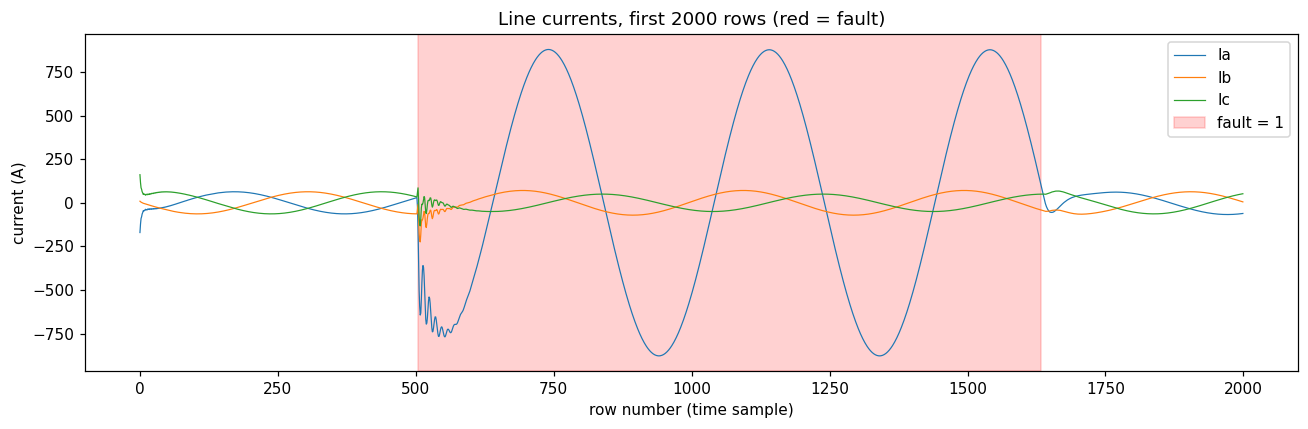

In [10]:
N = 2000
sub = df.iloc[:N]
f = sub["fault"].to_numpy().astype(int)

# contiguous runs of fault = 1
d = np.diff(np.r_[0, f, 0])
starts, ends = np.where(d == 1)[0], np.where(d == -1)[0]

fig, ax = plt.subplots(figsize=(12, 4))
for c, col in zip(["Ia", "Ib", "Ic"], ["tab:blue", "tab:orange", "tab:green"]):
    ax.plot(sub[c].to_numpy(), label=c, color=col, lw=0.8)
for k, (s, e) in enumerate(zip(starts, ends)):
    ax.axvspan(s, e, color="red", alpha=0.18, label="fault = 1" if k == 0 else None)
ax.set_xlabel("row number (time sample)"); ax.set_ylabel("current (A)")
ax.set_title("Line currents, first 2000 rows (red = fault)")
ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig("results/fig_eda_1_currents_time.png"); plt.show()

Before row ~500 the currents are small sinusoids of about ±60 A. At row ~500 Ia jumps to about −750 A with a transient, then swings ±880 A, roughly 14× normal. Ib and Ic stay small, so the fault is on phase A. At row ~1630 everything returns to normal.

### 2.2 Scatter of Ia vs Ib coloured by fault

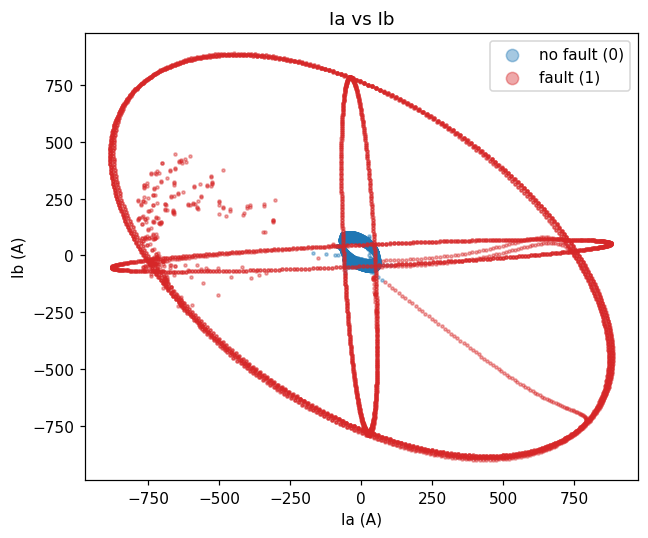

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
m0, m1 = df["fault"] == 0, df["fault"] == 1
ax.scatter(df.loc[m0, "Ia"], df.loc[m0, "Ib"], s=4, alpha=0.4, label="no fault (0)", color="tab:blue")
ax.scatter(df.loc[m1, "Ia"], df.loc[m1, "Ib"], s=4, alpha=0.4, label="fault (1)", color="tab:red")
ax.set_xlabel("Ia (A)"); ax.set_ylabel("Ib (A)"); ax.legend(markerscale=4)
ax.set_title("Ia vs Ib")
plt.tight_layout(); plt.savefig("results/fig_eda_2_scatter.png"); plt.show()

The no-fault (blue) points form a tiny cluster at the origin. The fault (red) points form large loops out to about ±880 A that surround that cluster, plus lines that pass through the centre.

### 2.3 Histogram of Ia for fault and no-fault rows

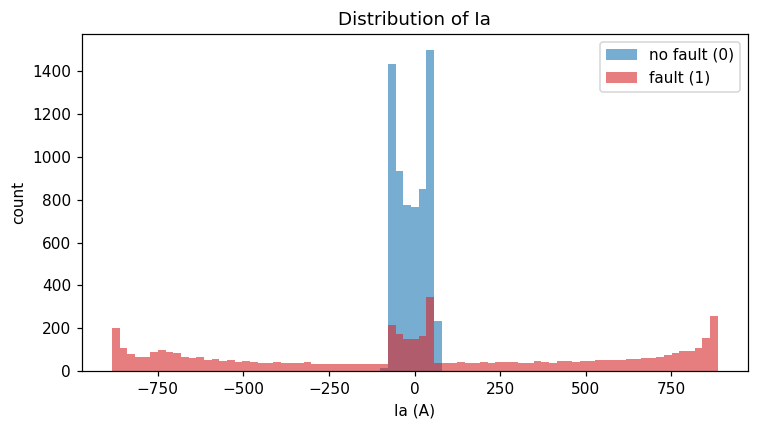

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(df["Ia"].min(), df["Ia"].max(), 80)
ax.hist(df.loc[m0, "Ia"], bins=bins, alpha=0.6, label="no fault (0)", color="tab:blue")
ax.hist(df.loc[m1, "Ia"], bins=bins, alpha=0.6, label="fault (1)", color="tab:red")
ax.set_xlabel("Ia (A)"); ax.set_ylabel("count"); ax.legend()
ax.set_title("Distribution of Ia")
plt.tight_layout(); plt.savefig("results/fig_eda_3_hist.png"); plt.show()

No-fault Ia lies only in about −75 to +75 A. Fault Ia is spread from −880 to +880 A, with peaks near ±880 and some fault rows overlapping the middle.

## Separability paragraph (write in your own words)
One line cannot separate them: the fault class sits on both sides of the no-fault class. A fault raises the amplitude, but the sinusoid swings both signs, so the signal is “large |I|”, not “large I”. A line only splits the plane into two half-planes, so it can’t isolate the middle region. Near zero crossings a fault row looks normal, so the classes also overlap.


## Task 3: Logistic regression by hand
Maths (n = training rows, x0 = 1):
- g(z) = 1 / (1 + e^(-z)), h(x) = g(theta^T x)
- J(theta) = -(1/n) * sum[ y log h + (1-y) log(1-h) ]
- Update: theta := theta + (alpha/n) * X^T (y - h)   (vectorised over all rows and all j)

### 3.1 to 3.3 Core functions

In [13]:
def add_ones(X):
    """Prepend the x0 = 1 column (intercept)."""
    return np.hstack([np.ones((X.shape[0], 1)), X])

def sigmoid(z):
    z = np.clip(z, -500, 500)          
    return 1.0 / (1.0 + np.exp(-z))

def hypothesis(X, theta):
    return sigmoid(X @ theta)

def cost(X, y, theta):
    h = np.clip(hypothesis(X, theta), 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(h) + (1 - y) * np.log(1 - h))

def fit_logistic(X, y, alpha, iters):
    """Batch gradient ascent on log-likelihood = gradient descent on J. Returns (theta, J_history)."""
    n = X.shape[0]
    theta = np.zeros(X.shape[1])
    J_hist = []
    for _ in range(iters):
        h = hypothesis(X, theta)
        theta = theta + (alpha / n) * (X.T @ (y - h))
        J_hist.append(cost(X, y, theta))
    return theta, np.array(J_hist)

def predict(X, theta):
    return (hypothesis(X, theta) >= 0.5).astype(int)

# Sanity check from the manual: J(0) must be log 2 = 0.693
XR_tr1 = add_ones(XR_tr)
print("J(theta = 0) =", round(cost(XR_tr1, y_tr, np.zeros(XR_tr1.shape[1])), 4), "| log 2 =", round(np.log(2), 4))

J(theta = 0) = 0.6931 | log 2 = 0.6931




### Build the two feature sets
- **Set R**: 6 raw features (already standardised above)
- **Set Q**: 6 raw + 6 squares. Squares are computed from the **raw** values first, then all 12 columns are standardised with training statistics.

In [14]:
# Set R (with intercept column)
XR_tr1, XR_val1, XR_te1 = add_ones(XR_tr), add_ones(XR_val), add_ones(XR_te)

# Set Q: squares from RAW values, THEN standardise all 12
def make_q_raw(Xraw):
    return np.hstack([Xraw, Xraw ** 2])

XQraw_tr, XQraw_val, XQraw_te = make_q_raw(Xr_tr_raw), make_q_raw(Xr_val_raw), make_q_raw(Xr_te_raw)
mu_Q, sd_Q = fit_scaler(XQraw_tr)
XQ_tr  = apply_scaler(XQraw_tr,  mu_Q, sd_Q)
XQ_val = apply_scaler(XQraw_val, mu_Q, sd_Q)
XQ_te  = apply_scaler(XQraw_te,  mu_Q, sd_Q)
XQ_tr1, XQ_val1, XQ_te1 = add_ones(XQ_tr), add_ones(XQ_val), add_ones(XQ_te)

print("Set R shape (with intercept):", XR_tr1.shape)
print("Set Q shape (with intercept):", XQ_tr1.shape)

Set R shape (with intercept): (7200, 7)
Set Q shape (with intercept): (7200, 13)


### 3.4 Choose alpha
2000 iterations for alpha in {0.01, 0.1, 1, 10}. Pick the **largest** alpha for which J decreases at every iteration.

Set R | alpha=0.01  final J=0.6772  monotone decreasing=True
Set R | alpha=0.1   final J=0.6772  monotone decreasing=True
Set R | alpha=1     final J=0.6772  monotone decreasing=True
Set R | alpha=10    final J=1.3439  monotone decreasing=False


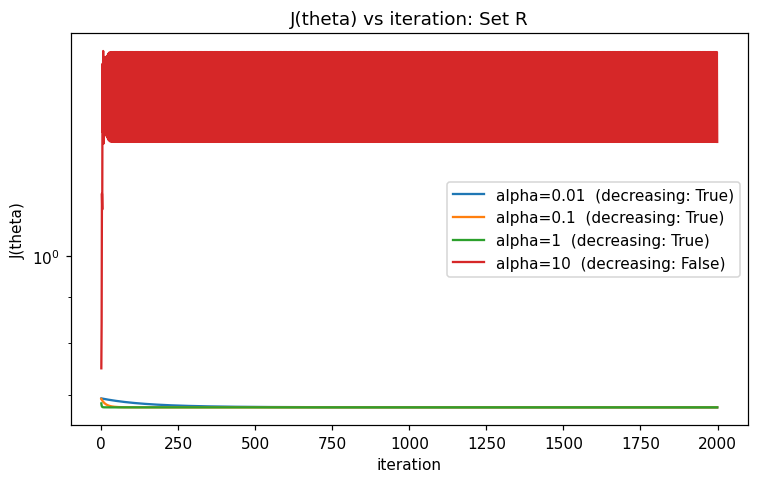

--> chosen alpha for Set R: 1

Set Q | alpha=0.01  final J=0.2006  monotone decreasing=True
Set Q | alpha=0.1   final J=0.1400  monotone decreasing=True
Set Q | alpha=1     final J=0.0890  monotone decreasing=True
Set Q | alpha=10    final J=0.0534  monotone decreasing=True


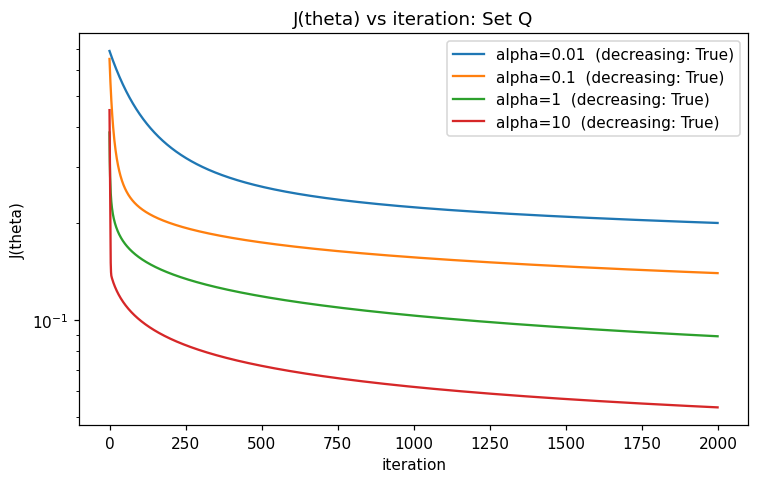

--> chosen alpha for Set Q: 10



In [15]:
ALPHAS = [0.01, 0.1, 1, 10]
ITERS = 2000
TOL = 1e-12 

def alpha_study(X1, y, title, fname):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ok = {}
    for a in ALPHAS:
        _, J = fit_logistic(X1, y, a, ITERS)
        monotone = bool(np.all(np.diff(J) <= TOL)) and np.all(np.isfinite(J))
        ok[a] = monotone
        ax.plot(J, label=f"alpha={a}  (decreasing: {monotone})")
        print(f"{title} | alpha={a:<5} final J={J[-1]:.4f}  monotone decreasing={monotone}")
    ax.set_xlabel("iteration"); ax.set_ylabel("J(theta)"); ax.set_title(f"J(theta) vs iteration: {title}")
    ax.set_yscale("log"); ax.legend()
    plt.tight_layout(); plt.savefig(fname); plt.show()
    chosen = max(a for a in ALPHAS if ok[a])
    print(f"--> chosen alpha for {title}: {chosen}\n")
    return chosen

alpha_R = alpha_study(XR_tr1, y_tr, "Set R", "results/fig_alpha_setR.png")
alpha_Q = alpha_study(XQ_tr1, y_tr, "Set Q", "results/fig_alpha_setQ.png")


### 3.5 Final models: accuracy, theta, Table 2 and Table 5

In [16]:
def accuracy(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))

theta_R, J_R = fit_logistic(XR_tr1, y_tr, alpha_R, ITERS)
theta_Q, J_Q = fit_logistic(XQ_tr1, y_tr, alpha_Q, ITERS)

rowsT2 = []
for name, th, J, Xtr1, Xval1, a in [("Set R", theta_R, J_R, XR_tr1, XR_val1, alpha_R),
                                    ("Set Q", theta_Q, J_Q, XQ_tr1, XQ_val1, alpha_Q)]:
    tr_acc  = accuracy(y_tr,  predict(Xtr1, th))
    val_acc = accuracy(y_val, predict(Xval1, th))
    print(f"{name}: alpha={a}, final J={J[-1]:.4f}, train acc={tr_acc:.4f}, val acc={val_acc:.4f}")
    rowsT2.append({"Feature set": name, "Chosen alpha": a, "Final J(theta)": round(J[-1], 4),
                   "Train accuracy": round(tr_acc, 4), "Validation accuracy": round(val_acc, 4)})

table2 = pd.DataFrame(rowsT2)
table2.to_csv("results/table2_logistic.csv", index=False)
display(table2)

names_Q = ["theta0 (intercept)", "Ia", "Ib", "Ic", "Va", "Vb", "Vc", "Ia^2", "Ib^2", "Ic^2", "Va^2", "Vb^2", "Vc^2"]
table5 = pd.DataFrame({"weight": names_Q, "value": theta_Q.round(4)})
table5.to_csv("results/table5_theta_setQ.csv", index=False)
print("\ntheta (Set R):", theta_R.round(4))
display(table5)

Set R: alpha=1, final J=0.6772, train acc=0.7258, val acc=0.7308
Set Q: alpha=10, final J=0.0534, train acc=0.9788, val acc=0.9783


,Feature set,Chosen alpha,Final J(theta),Train accuracy,Validation accuracy
0,Set R,1,0.6772,0.7258,0.7308
1,Set Q,10,0.0534,0.9788,0.9783



theta (Set R): [-0.161   0.0898 -0.1367  0.2171 -0.0575  0.0544  0.001 ]


,weight,value
0,theta0 (intercept),24.9209
1,Ia,2.3273
2,Ib,-5.3581
3,Ic,-1.7365
4,Va,-0.5336
5,Vb,0.4167
6,Vc,0.0986
7,Ia^2,18.8912
8,Ib^2,4.7543
9,Ic^2,13.9569


## Task 4: Support vector machines (Set R only)
Linear SVM may take a little while for large C. That is normal.

In [17]:
import time
Cs = [0.1, 1, 10, 100]
gammas = [0.1, 1]
rows, models = [], {}

for C in Cs:
    t0 = time.time()
    m = SVC(kernel="linear", C=C).fit(XR_tr, y_tr)
    acc = accuracy(y_val, m.predict(XR_val))
    rows.append({"Kernel": "linear", "C": C, "gamma": "-", "Val accuracy": round(acc, 4), "Support vectors": int(m.n_support_.sum())})
    models[("linear", C, None)] = m
    print(f"linear C={C}: val acc={acc:.4f}  SV={m.n_support_.sum()}  ({time.time()-t0:.1f}s)")

for C in Cs:
    for g in gammas:
        t0 = time.time()
        m = SVC(kernel="rbf", C=C, gamma=g).fit(XR_tr, y_tr)
        acc = accuracy(y_val, m.predict(XR_val))
        rows.append({"Kernel": "rbf", "C": C, "gamma": g, "Val accuracy": round(acc, 4), "Support vectors": int(m.n_support_.sum())})
        models[("rbf", C, g)] = m
        print(f"rbf    C={C}, gamma={g}: val acc={acc:.4f}  SV={m.n_support_.sum()}  ({time.time()-t0:.1f}s)")

table3 = pd.DataFrame(rows)
table3.to_csv("results/table3_svm_validation.csv", index=False)
table3

linear C=0.1: val acc=0.7258  SV=5849  (2.3s)
linear C=1: val acc=0.7258  SV=5841  (3.6s)
linear C=10: val acc=0.7258  SV=5833  (11.5s)
linear C=100: val acc=0.7258  SV=5835  (56.7s)
rbf    C=0.1, gamma=0.1: val acc=0.9500  SV=1347  (1.0s)
rbf    C=0.1, gamma=1: val acc=0.9804  SV=848  (0.6s)
rbf    C=1, gamma=0.1: val acc=0.9750  SV=723  (0.5s)
rbf    C=1, gamma=1: val acc=0.9917  SV=482  (0.4s)
rbf    C=10, gamma=0.1: val acc=0.9921  SV=381  (0.3s)
rbf    C=10, gamma=1: val acc=0.9962  SV=342  (0.3s)
rbf    C=100, gamma=0.1: val acc=0.9954  SV=174  (0.2s)
rbf    C=100, gamma=1: val acc=0.9967  SV=266  (0.3s)


,Kernel,C,gamma,Val accuracy,Support vectors
0,linear,0.1,-,0.7258,5849
1,linear,1.0,-,0.7258,5841
2,linear,10.0,-,0.7258,5833
3,linear,100.0,-,0.7258,5835
4,rbf,0.1,0.1,0.9500,1347
5,rbf,0.1,1,0.9804,848
6,rbf,1.0,0.1,0.9750,723
7,rbf,1.0,1,0.9917,482
8,rbf,10.0,0.1,0.9921,381
9,rbf,10.0,1,0.9962,342


best linear: ('linear', 0.1, None) | best rbf: ('rbf', 100, 1)


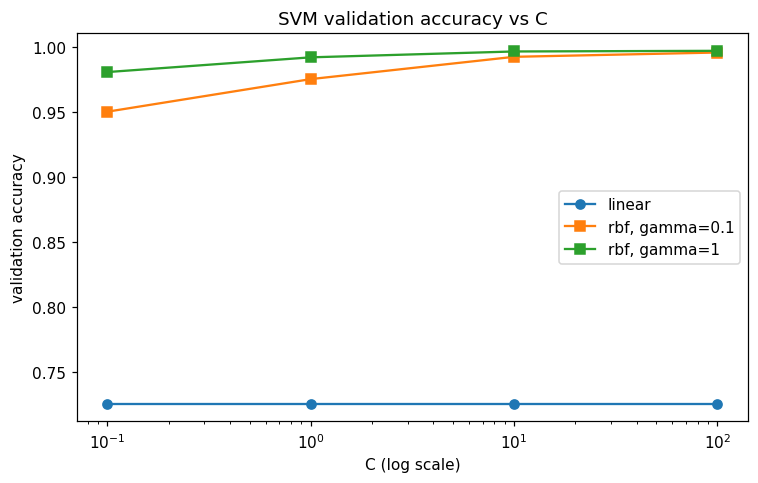

In [18]:
def best_of(kernel):
    cand = [(k, m) for k, m in models.items() if k[0] == kernel]
    return max(cand, key=lambda km: accuracy(y_val, km[1].predict(XR_val)))

(best_lin_key, svm_lin), (best_rbf_key, svm_rbf) = best_of("linear"), best_of("rbf")
print("best linear:", best_lin_key, "| best rbf:", best_rbf_key)
joblib.dump(svm_lin, "results/svm_linear_best.joblib")
joblib.dump(svm_rbf, "results/svm_rbf_best.joblib")

# Figure 3: validation accuracy vs C (log x-axis)
fig, ax = plt.subplots(figsize=(7, 4.5))
lin = table3[table3.Kernel == "linear"]
ax.plot(lin["C"], lin["Val accuracy"], "o-", label="linear")
for g in gammas:
    r = table3[(table3.Kernel == "rbf") & (table3.gamma == g)]
    ax.plot(r["C"], r["Val accuracy"], "s-", label=f"rbf, gamma={g}")
ax.set_xscale("log"); ax.set_xlabel("C (log scale)"); ax.set_ylabel("validation accuracy")
ax.set_title("SVM validation accuracy vs C"); ax.legend()
plt.tight_layout(); plt.savefig("results/fig_svm_val_vs_C.png"); plt.show()


## Task 5: Test once

In [19]:
def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))  
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))  
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    return np.array([[tn, fp], [fn, tp]])

final = {
    "Logistic regression, Set R": predict(XR_te1, theta_R),
    "Logistic regression, Set Q": predict(XQ_te1, theta_Q),
    f"Linear SVM (C={best_lin_key[1]})": svm_lin.predict(XR_te).astype(int),
    f"RBF SVM (C={best_rbf_key[1]}, gamma={best_rbf_key[2]})": svm_rbf.predict(XR_te).astype(int),
}

rows4 = []
for name, yp in final.items():
    cm = confusion_matrix(y_te, yp)
    assert cm.sum() == len(y_te), "confusion matrix must add up to the number of test rows"
    rows4.append({"Model": name, "Accuracy": round(accuracy(y_te, yp), 4),
                  "TN": cm[0, 0], "False alarms": cm[0, 1], "Missed faults": cm[1, 0], "TP": cm[1, 1]})
table4 = pd.DataFrame(rows4)
table4.to_csv("results/table4_test.csv", index=False)
print("test rows:", len(y_te))
table4

test rows: 2401


,Model,Accuracy,TN,False alarms,Missed faults,TP
0,"Logistic regression, Set R",0.7264,1305,0,657,439
1,"Logistic regression, Set Q",0.9788,1299,6,45,1051
2,Linear SVM (C=0.1),0.7359,1305,0,634,462
3,"RBF SVM (C=100, gamma=1)",0.9958,1301,4,6,1090




## Task 6: Analysis helpers
These cells print the evidence; the written answers must be in your own words (blog + `results/analysis.md`).



In [20]:
print(table5.to_string(index=False))
print("\nmean of I^2 weights:", theta_Q[7:10].mean().round(3))
print("mean of V^2 weights:", theta_Q[10:13].mean().round(3))

            weight   value
theta0 (intercept) 24.9209
                Ia  2.3273
                Ib -5.3581
                Ic -1.7365
                Va -0.5336
                Vb  0.4167
                Vc  0.0986
              Ia^2 18.8912
              Ib^2  4.7543
              Ic^2 13.9569
              Va^2 -6.0276
              Vb^2 -6.4643
              Vc^2 -6.1407

mean of I^2 weights: 12.534
mean of V^2 weights: -6.211


In [21]:
print("Linear SVM support vectors:", int(svm_lin.n_support_.sum()), "of", len(y_tr), "training rows")
print("RBF SVM support vectors   :", int(svm_rbf.n_support_.sum()), "of", len(y_tr), "training rows")
table3.sort_values(["Kernel", "C"])

Linear SVM support vectors: 5849 of 7200 training rows
RBF SVM support vectors   : 266 of 7200 training rows


,Kernel,C,gamma,Val accuracy,Support vectors
0,linear,0.1,-,0.7258,5849
1,linear,1.0,-,0.7258,5841
2,linear,10.0,-,0.7258,5833
3,linear,100.0,-,0.7258,5835
4,rbf,0.1,0.1,0.9500,1347
5,rbf,0.1,1,0.9804,848
6,rbf,1.0,0.1,0.9750,723
7,rbf,1.0,1,0.9917,482
8,rbf,10.0,0.1,0.9921,381
9,rbf,10.0,1,0.9962,342


In [22]:
n = len(df)
tr_t, va_t, te_t = np.arange(0, int(.6*n)), np.arange(int(.6*n), int(.8*n)), np.arange(int(.8*n), n)

mu_t, sd_t = fit_scaler(X_raw[tr_t])
Xt_tr, Xt_te = apply_scaler(X_raw[tr_t], mu_t, sd_t), apply_scaler(X_raw[te_t], mu_t, sd_t)
m_time = SVC(kernel="rbf", C=best_rbf_key[1], gamma=best_rbf_key[2]).fit(Xt_tr, y_all[tr_t])
print("RBF SVM, time-ordered split test accuracy:", round(accuracy(y_all[te_t], m_time.predict(Xt_te)), 4))
print("RBF SVM, random split test accuracy      :", round(accuracy(y_te, final[list(final)[3]]), 4))

RBF SVM, time-ordered split test accuracy: 0.9938
RBF SVM, random split test accuracy      : 0.9958


**6.1: both are linear boundaries and score 72.64% and 73.59%. The bottleneck is the boundary’s shape, not the training method. The majority-class baseline is 54.3%.**
**6.2: I² weights are positive (+18.9, +4.8, +14.0) because current rises in a fault. V² weights are negative (−6.0, −6.5, −6.1) because voltage sags. Explain why squaring removes the sign problem.**
**6.3: linear uses 5849 of 7200 points (81%) as support vectors, and RBF uses 266 (3.7%). Explain what a support vector is, and what it means when most points are support vectors.**
**6.4: linear accuracy stays flat (SV 5849 → 5835). For RBF at γ=0.1, accuracy goes 0.9500 → 0.9954 and SV goes 1347 → 174. Explain using what C penalises (margin violations).**
**6.5: neighbouring samples are near-duplicates, so a random split leaks. Your experiment gave 0.9958 vs 0.9938, a small drop but on different test sets. Add what a real relay faces that the simulation lacks (noise, other fault types, resistances, locations). State your view and justify it.**
**6.6: the linear/R models never raise a false alarm, but they miss 634-657 of the 1096 test faults (about 58-60%). LR Q misses 45. RBF misses 6 with 4 false alarms. Argue from missed faults, since a missed fault means the breaker doesn’t trip.**

In [23]:
np.savez("results/preprocessing.npz", mu_R=mu_R, sd_R=sd_R, mu_Q=mu_Q, sd_Q=sd_Q)
np.savez("results/theta.npz", theta_R=theta_R, theta_Q=theta_Q)
print(os.listdir("results"))

['fig_alpha_setQ.png', 'fig_alpha_setR.png', 'fig_eda_1_currents_time.png', 'fig_eda_2_scatter.png', 'fig_eda_3_hist.png', 'fig_svm_val_vs_C.png', 'preprocessing.npz', 'svm_linear_best.joblib', 'svm_rbf_best.joblib', 'table1_data_prep.csv', 'table2_logistic.csv', 'table3_svm_validation.csv', 'table4_test.csv', 'table5_theta_setQ.csv', 'theta.npz']


In [27]:
%%writefile results/analysis.md
# Task 6: Analysis

## 6.1 LR (Set R) vs linear SVM
Numbers: LR-R test acc 72.64%, linear SVM 73.59%.
Answer: Both are linear boundaries and score 72.64% and 73.59%. The bottleneck is the boundary’s shape, not the training method. 
The majority-class baseline is 54.3%.

## 6.2 Signs of I^2 and V^2 weights (Set Q)
Numbers: I^2 weights = +18.89, +4.75, +13.96; V^2 weights = -6.03, -6.46, -6.14.
Answer:I² weights are positive (+18.9, +4.8, +14.0) because current rises in a fault. V² weights are negative (−6.0, −6.5, −6.1) because voltage sags.
Explain why squaring removes the sign problem.

## 6.3 Support vectors, linear vs RBF
Numbers: linear 5849 / 7200; RBF 266 / 7200.
Answer: linear uses 5849 of 7200 points (81%) as support vectors, and RBF uses 266 (3.7%). Explain what a support vector is, 
and what it means when most points are support vectors.

## 6.4 Accuracy and support vectors as C increases
Numbers: linear accuracy stays 0.7258 for every C; RBF gamma=0.1: 0.9500 -> 0.9954, SV 1347 -> 174.
Answer:inear accuracy stays flat (SV 5849 → 5835). For RBF at γ=0.1, accuracy goes 0.9500 → 0.9954 and SV goes 1347 → 174.
Explain using what C penalises (margin violations).

## 6.5 Random split: optimistic or pessimistic?
Numbers: random split 0.9958 vs time-ordered 0.9938 (different test sets).
Answer: neighbouring samples are near-duplicates, so a random split leaks. Your experiment gave 0.9958 vs 0.9938, a small drop but on different test sets. Add what a real relay faces that the simulation lacks (noise, other fault types, resistances, locations). 
State your view and justify it.

    ## 6.6 Which model to deploy?
Numbers (missed faults / false alarms): LR-R 657/0, LR-Q 45/6, linear SVM 634/0, RBF 6/4.
Answer: The linear/R models never raise a false alarm, but they miss 634-657 of the 1096 test faults (about 58-60%). LR Q misses 45. RBF misses 6 with 4 false alarms. Argue from missed faults, 
since a missed fault means the breaker doesn’t trip.


Overwriting results/analysis.md


## Task 7: front end (Streamlit)

In [25]:
%%writefile app/app.py
import numpy as np
import joblib
import streamlit as st

st.title("Three-phase line fault detector")
st.write("Enter one instant of measurements.")

pre = np.load("results/preprocessing.npz")
theta_Q = np.load("results/theta.npz")["theta_Q"]
svm = joblib.load("results/svm_rbf_best.joblib")

c1, c2 = st.columns(2)
Ia = c1.number_input("Ia (A)", value=0.0, format="%.4f")
Ib = c1.number_input("Ib (A)", value=0.0, format="%.4f")
Ic = c1.number_input("Ic (A)", value=0.0, format="%.4f")
Va = c2.number_input("Va (pu)", value=0.0, format="%.4f")
Vb = c2.number_input("Vb (pu)", value=0.0, format="%.4f")
Vc = c2.number_input("Vc (pu)", value=0.0, format="%.4f")

if st.button("Predict"):
    raw6 = np.array([[Ia, Ib, Ic, Va, Vb, Vc]])

    q = np.hstack([raw6, raw6 ** 2])
    q = (q - pre["mu_Q"]) / pre["sd_Q"]
    q1 = np.hstack([np.ones((1, 1)), q])
    p = float(1 / (1 + np.exp(-(q1 @ theta_Q))))
    lr_pred = int(p >= 0.5)

    r = (raw6 - pre["mu_R"]) / pre["sd_R"]
    svm_pred = int(svm.predict(r)[0])

    a, b = st.columns(2)
    a.subheader("Logistic regression (Set Q)")
    a.metric("Prediction", "FAULT" if lr_pred else "no fault", f"P(fault) = {p:.3f}")
    b.subheader("RBF SVM")
    b.metric("Prediction", "FAULT" if svm_pred else "no fault")

Overwriting app/app.py
